In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
import numpy as np
import seaborn as sns

In [ ]:
# def visualize_solutions(solutions, alpha):
#     # 'solutions' is a numpy array of shape (num_sols, N)
#     data = np.array(solutions)
    
#     # Project to 2D
#     tsne = TSNE(n_components=2, perplexity=min(30, len(data)-1), random_state=42)
#     embedded = tsne.fit_transform(data)
    
#     plt.scatter(embedded[:, 0], embedded[:, 1], s=5, alpha=0.5)
#     plt.title(f"Solution Space Structure at alpha={alpha}")
#     plt.show()

In [2]:
df = pd.read_csv("../results/solution_space_coords.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../results/solution_space_coords.csv'

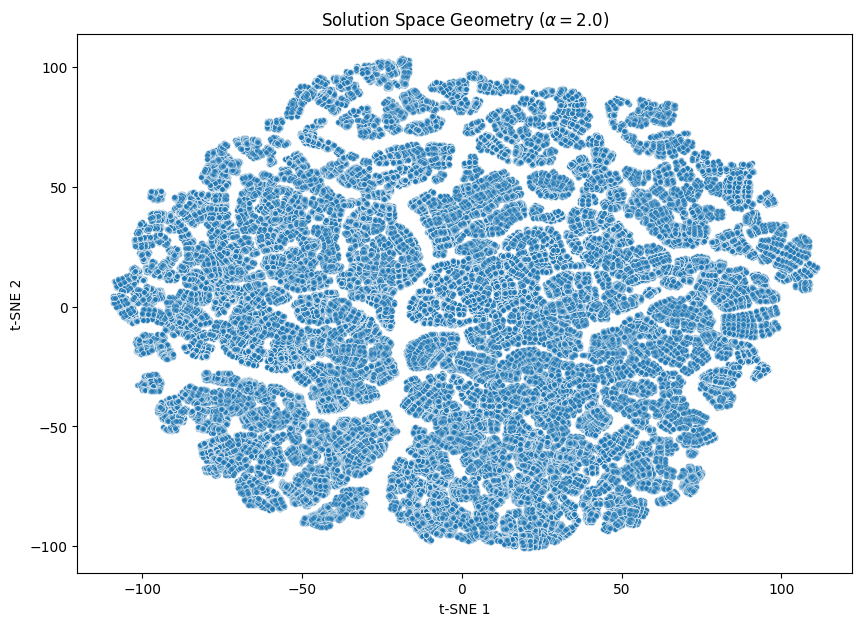

In [ ]:
# Load the data
df = pd.read_csv("../results/csv/solution_space_coords.csv")

# Filter for alpha 2.0 if you have multiple
df_alpha = df[df['alpha'] == 2.0]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_alpha, x='x', y='y', alpha=0.5, s=15)
# plt.scatter(df_alpha['x'], df_alpha['y'], alpha=0.5, s=15)
plt.title("Solution Space Geometry ($\\alpha = 2.0$)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

Alphas found in CSV: [0.2 0.5 0.8 1.  1.2 1.4]


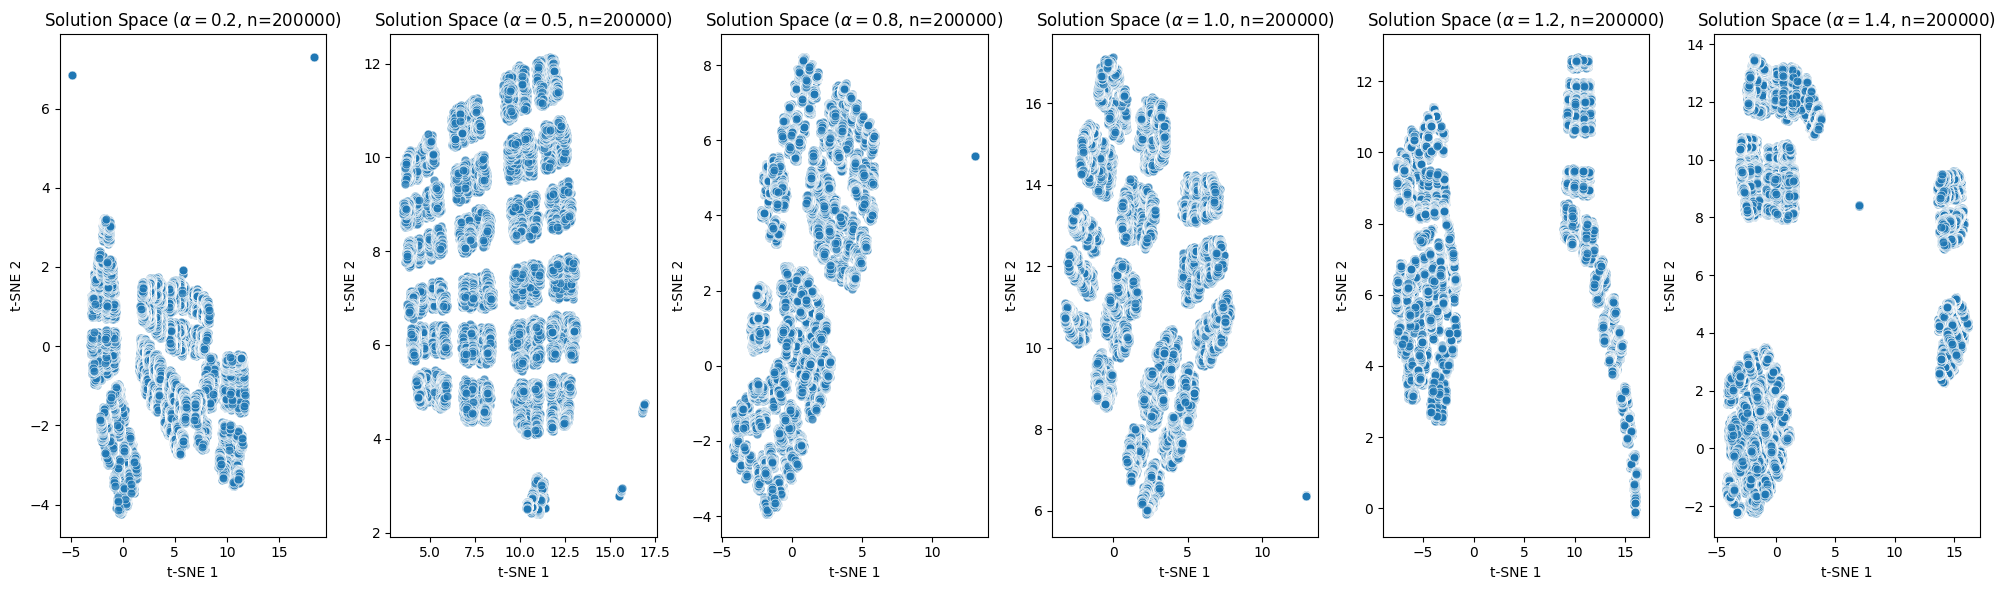

In [ ]:
df = pd.read_csv("../results/csv/solution_space_coords_N=50.csv") 

print("Alphas found in CSV:", df['alpha'].unique())

fig, axes = plt.subplots(1, 6, figsize=(20, 6))

for i, a in enumerate(df['alpha'].unique()[:6]): # Plot the first six alphas found
    subset = df[df['alpha'] == a]
    sns.scatterplot(data=subset, x='x', y='y', alpha=0.7, s=40, ax=axes[i])
    # sns.kdeplot(x=subset['x'], y=subset['y'], fill=True, ax=axes[i], cmap="viridis", thresh=0.05)
    axes[i].set_title(f"Solution Space ($\\alpha = {a}$, n={len(subset)})")
    axes[i].set_xlabel("t-SNE 1")
    axes[i].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()


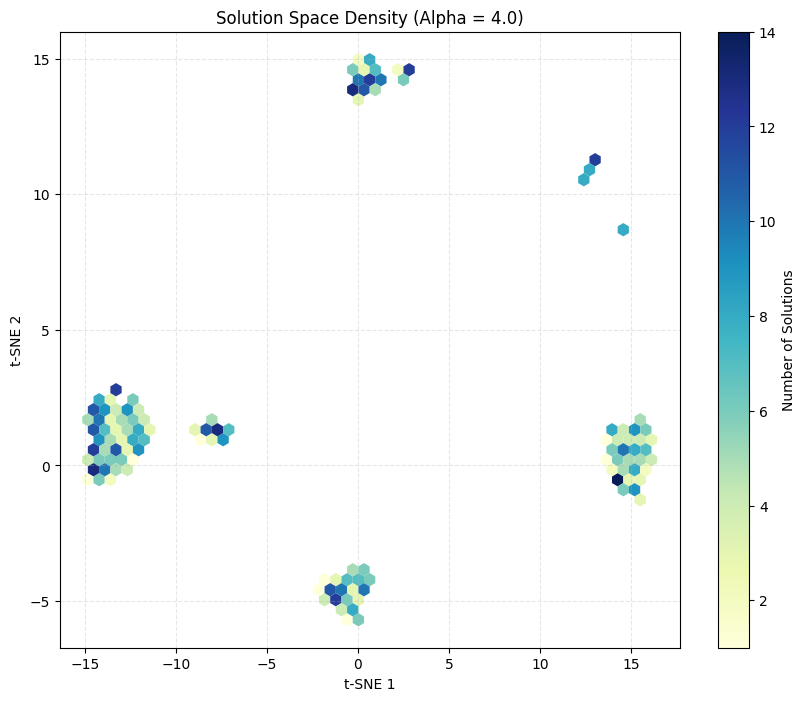

In [13]:
# import seaborn as sns
# from scipy.spatial.distance import pdist, squareform

# # Assuming 'subset' is your alpha = 4.1 dataframe with the raw solution bits
# # If you only have x,y coords, we can't do this - you'd need the raw 0/1 vectors
# def plot_hamming_heatmap(solutions, alpha):
#     distances = squareform(pdist(solutions, metric='cityblock'))
#     plt.figure(figsize=(8, 6))
#     sns.heatmap(distances, annot=True, cmap="YlGnBu")
#     plt.title(f"Pairwise Hamming Distances at $\\alpha = {alpha}$")
#     plt.show()


def plot_hexbin_space(df, alpha_val):
    subset = df[df['alpha'] == alpha_val]
    
    plt.figure(figsize=(10, 8))
    
    # gridsize: higher means more detail/smaller hexagons
    # mincnt=1: prevents plotting hexagons where there are 0 solutions
    hb = plt.hexbin(subset['x'], subset['y'], 
                    gridsize=50, 
                    cmap='YlGnBu', 
                    mincnt=1, 
                    edgecolors='none')
    
    cb = plt.colorbar(hb)
    cb.set_label('Number of Solutions')
    
    plt.title(f"Solution Space Density (Alpha = {alpha_val})")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()

# Example usage:
plot_hexbin_space(df, 4.0)


Sampling solution space...
Collected 5000 solutions. Running UMAP...


/Users/sasha/Documents/BSc_Thesis/SAT_Phase_Transition_Benchmark/.venv/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for hamming distance metric; inverse_transform will be unavailable
  warn(


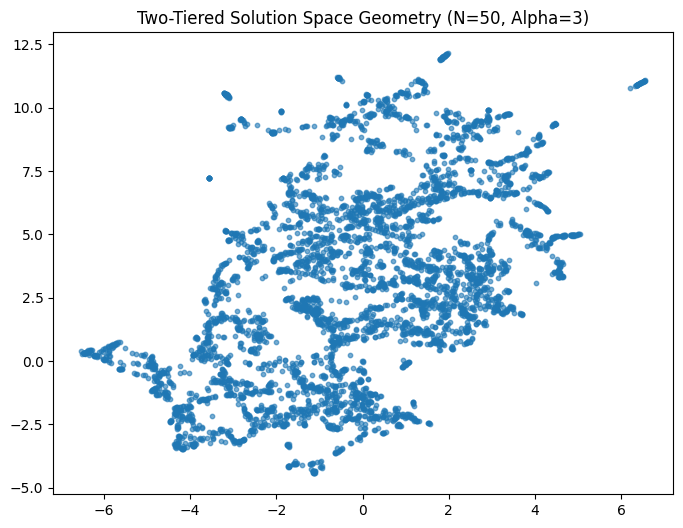

In [34]:
import random
import numpy as np
import pandas as pd
import umap
import matplotlib.pyplot as plt

def generate_random_3sat(n, alpha):
    """Generates a random 3-SAT formula."""
    m = int(n * alpha)
    clauses = []
    variables = list(range(1, n + 1))
    for _ in range(m):
        vars_ = random.sample(variables, 3)
        clauses.append([v if random.random() < 0.5 else -v for v in vars_])
    return clauses

def evaluate_clause(clause, assignment):
    """Checks if a clause is satisfied."""
    return any((lit > 0 and assignment[lit] == 1) or 
               (lit < 0 and assignment[-lit] == 0) for lit in clause)

def walksat_solve(clauses, n, initial_assignment=None, max_flips=1000):
    """Basic WalkSAT implementation for local search."""
    if initial_assignment is None:
        assignment = {i: random.choice([0, 1]) for i in range(1, n + 1)}
    else:
        assignment = initial_assignment.copy()
        
    for _ in range(max_flips):
        unsat_clauses = [c for c in clauses if not evaluate_clause(c, assignment)]
        
        if not unsat_clauses:
            return assignment # Found a solution!
            
        # Pick a random unsatisfied clause
        clause = random.choice(unsat_clauses)
        
        # With some probability (noise), flip a random variable in the clause
        if random.random() < 0.4:
            var_to_flip = abs(random.choice(clause))
        else:
            # Otherwise, flip the one that causes the least "damage" 
            # (Simplified here to just a random choice for speed in Python, 
            # true WalkSAT calculates break-counts)
            var_to_flip = abs(random.choice(clause))
            
        assignment[var_to_flip] = 1 - assignment[var_to_flip]
        
    return None # Failed to find solution in max_flips

def collect_solutions(n, alpha, num_clusters=50, solutions_per_cluster=100):
    """The Two-Tiered Sampling Strategy."""
    clauses = generate_random_3sat(n, alpha)
    all_solutions = []
    
    for cluster_id in range(num_clusters):
        # 1. GLOBAL JUMP: Start from completely random assignment
        base_solution = walksat_solve(clauses, n)
        
        if base_solution:
            # 2. LOCAL EXPLORATION: Wander around this cluster
            for _ in range(solutions_per_cluster):
                # "Kick" the solution by flipping 2 random variables
                perturbed = base_solution.copy()
                vars_to_flip = random.sample(list(range(1, n + 1)), 2)
                for v in vars_to_flip:
                    perturbed[v] = 1 - perturbed[v]
                
                # Let WalkSAT fix the broken assignment
                local_solution = walksat_solve(clauses, n, initial_assignment=perturbed)
                
                if local_solution:
                    sol_vector = [local_solution[i] for i in range(1, n + 1)]
                    all_solutions.append(sol_vector)
                    # Update base to wander further through the cluster
                    base_solution = local_solution 
                    
    return np.array(all_solutions)

# --- Execution and UMAP ---
N = 50
ALPHA = 3 # Right around the shattering transition for 3-SAT

print("Sampling solution space...")
data = collect_solutions(N, ALPHA)

print(f"Collected {len(data)} solutions. Running UMAP...")
reducer = umap.UMAP(n_neighbors=15, metric='hamming', min_dist=0.1)
embedding = reducer.fit_transform(data)

plt.figure(figsize=(8, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], alpha=0.6, s=10)
plt.title(f"Two-Tiered Solution Space Geometry (N={N}, Alpha={ALPHA})")
plt.show()